<a href="https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/02_policy_gradient_reinforce.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Train Your RL Agent** · [Ch 1 · Q-learning](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/01_q_learning_tool_agent.ipynb) → **📍 Ch 2 · REINFORCE** → [Ch 3 · GRPO](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/03_grpo_from_scratch.ipynb) → [Ch 4 · LLM + tools](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/04_llm_tool_use_grpo.ipynb)

# 🎲 Chapter 2 · Policy gradients: learn with probabilities

### The big idea

In [Chapter 1](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/01_q_learning_tool_agent.ipynb) the agent kept a **score** for every button and pressed the best one.

Language models don't work like that. They choose each word by **probability**: *"the next word is `the` with 31%, `a` with 12%..."*

So in this chapter the agent learns probabilities directly, with one simple rule:

> **If an attempt went better than usual, make its choices more likely. If it went worse, make them less likely.**

That rule is called **REINFORCE**. It's the ancestor of PPO and GRPO, the methods that train today's LLM agents.

✅ Free CPU · ✅ About 1 minute · ✅ No installations (PyTorch comes with Colab)

## 1 · Scores vs. probabilities 🤔

| | Chapter 1: Q-learning | Chapter 2: policy gradient |
|:--|:--|:--|
| What the agent stores | a **score** for each button | a **probability** for each button |
| How it picks | the highest score | it rolls a weighted die 🎲 |
| How it explores | we added random moves | built in: unlikely buttons still come up sometimes |
| What it learns from | each step, plus a guess about the future | the total reward of the whole attempt |
| Used for LLMs? | rarely | **yes** (PPO, GRPO) |

## 2 · The same tiny world 🌍

The buttons, tools, questions and rewards are exactly the same as in Chapter 1.

In [1]:
import random
import torch
import matplotlib.pyplot as plt

random.seed(0)
torch.manual_seed(0)
plt.rcParams.update({"figure.dpi": 110, "font.size": 12, "axes.titlesize": 14, "axes.titleweight": "bold",
                     "axes.spines.top": False, "axes.spines.right": False})
ACCENT, GREY, GOOD, BAD = "#2563EB", "#9AA4AE", "#16803C", "#C2413A"   # course colors

buttons = ["Calculator", "Dictionary", "Reply", "Finish"]
topics = ["math", "words", "chat"]

In [2]:
meanings = {
    "orbit": "a path around another object",
    "habitat": "an animal's natural home",
    "gravity": "a force pulling things together",
}
greetings = {"hello": "Hello!", "thanks": "You're welcome!"}

def use_tool(button, task):
    kind, question, data = task
    if button == "Calculator" and kind == "math":
        return str(data[0] * data[1])
    if button == "Dictionary" and kind == "words":
        return meanings[data]
    if button == "Reply" and kind == "chat":
        return greetings[data]
    return None  # Wrong tool: no answer

In [3]:
practice = [
    ("math", "What is 3 x 4?", (3, 4)),
    ("math", "What is 6 x 8?", (6, 8)),
    ("words", "Define orbit", "orbit"),
    ("words", "Define habitat", "habitat"),
    ("chat", "Say hello", "hello"),
    ("chat", "Say thanks", "thanks"),
]
test_tasks = [  # never used for practice
    ("math", "What is 9 x 11?", (9, 11)),
    ("words", "Define gravity", "gravity"),
    ("chat", "Say hello to my friend", "hello"),
]

The reward rules are unchanged too: **+1** for finishing with an answer, **−1** for finishing without one, **−0.15** for a wrong tool, and **−0.02** for a useful tool.

In [4]:
def step(task, state, button, answer):
    topic, stage = state
    if button == "Finish":
        return state, (1 if answer else -1), True, answer
    result = use_tool(button, task)
    if result is not None:
        return (topic, "has_answer"), -0.02, False, result
    return state, -0.15, False, answer

## 3 · The new brain: a policy 🧠

For each of the six situations, the agent keeps **four preference numbers**, one per button. (In ML these are called **logits**.)

A function called **softmax** turns preferences into probabilities that add up to 100%. A bigger preference gives a bigger probability.

At the start every preference is **0**, so every button has the same chance.

In [5]:
states = [(topic, stage) for topic in topics for stage in ("needs_tool", "has_answer")]
state_id = {state: i for i, state in enumerate(states)}

def new_policy():
    # 6 situations x 4 buttons, all starting at 0
    return torch.zeros(len(states), len(buttons), requires_grad=True)

def probabilities(policy, state):
    return torch.softmax(policy[state_id[state]], dim=0)

policy = new_policy()
print("Math, before training:", probabilities(policy, ("math", "needs_tool")))

Math, before training: tensor([0.2500, 0.2500, 0.2500, 0.2500], grad_fn=<SoftmaxBackward0>)


**What just happened?** All four preferences are 0, so softmax gives every button **25%**. The agent has no idea yet.

`requires_grad=True` asks PyTorch to keep track of how each number should change to make the agent better. That's the "gradient" in *policy gradient*.

### 🔍 Try it: what does softmax do?

Change the preferences and rerun. What happens when one number is much bigger than the others?

In [6]:
preferences = torch.tensor([2.0, 0.0, 0.0, 0.0])  # 👈 try [5, 0, 0, 0] or [1, 1, 1, 1]
for button, p in zip(buttons, torch.softmax(preferences, dim=0)):
    print(f"{button:10} {p:.0%}")

Calculator 71%
Dictionary 10%
Reply      10%
Finish     10%


**What just happened?** A preference of 2 against three zeros already gives the first button about **71%**. The other buttons still keep about 10% each, so the agent keeps exploring.

#### Going deeper (optional): the softmax formula

If the preferences are $z_1, \dots, z_4$, the probability of button $i$ is

$$p_i = \frac{e^{z_i}}{e^{z_1} + e^{z_2} + e^{z_3} + e^{z_4}}$$

Raising $e$ to each preference makes every value positive. Dividing by the total makes them add up to 1.

### Picking a button = rolling a weighted die 🎲

During training the agent **samples** a button from its probabilities, so likely buttons come up often and unlikely ones still come up sometimes. For testing we can also make it **greedy**, so it always picks the most likely button.

In [7]:
def choose_button(policy, state, greedy=False):
    p = probabilities(policy, state)
    if greedy:
        return int(p.argmax())
    return int(torch.multinomial(p, 1))

rolls = [buttons[choose_button(policy, ("math", "needs_tool"))] for _ in range(8)]
print("Eight rolls of an untrained agent:", rolls)

Eight rolls of an untrained agent: ['Reply', 'Reply', 'Finish', 'Calculator', 'Dictionary', 'Reply', 'Calculator', 'Dictionary']


## 4 · Play an episode and remember each choice 📝

To learn, the agent must remember **how likely each of its choices was**. We store the **log** of each probability, called the **log-prob**.

A log-prob is just another scale for "how likely was that choice?". **0** means certain, and very negative means very unlikely. LLM training code is full of log-probs.

In [8]:
def run_episode(policy, task, greedy=False):
    state, answer = (task[0], "needs_tool"), None
    total_reward, log_probs, trail = 0.0, [], []
    for move in range(4):
        b = choose_button(policy, state, greedy)
        log_probs.append(torch.log(probabilities(policy, state)[b]))
        state, points, done, answer = step(task, state, buttons[b], answer)
        if move == 3 and not done:
            points -= 0.5  # Running out of moves is bad
        total_reward += points
        trail.append((buttons[b], points, answer))
        if done:
            break
    success = bool(done and answer)
    return total_reward, torch.stack(log_probs), success, trail

In [9]:
example = ("math", "What is 7 x 8?", (7, 8))
total, log_probs, success, trail = run_episode(policy, example)
for button, points, answer in trail:
    print(f"Pressed {button:10} | reward {points:+.2f} | answer: {answer}")
print(f"Total reward: {total:+.2f} | success: {success}")
print("Log-probs of its choices:", log_probs.detach().numpy().round(2))

Pressed Dictionary | reward -0.15 | answer: None
Pressed Finish     | reward -1.00 | answer: None
Total reward: -1.15 | success: False
Log-probs of its choices: [-1.39 -1.39]


**What just happened?** The untrained agent pressed random buttons. Every choice had a 25% chance, so every log-prob is the same: log(0.25) ≈ **−1.39**.

## 5 · The REINFORCE rule 🔁

After every attempt, the agent asks one question:

> **Was this attempt better or worse than I usually do?**

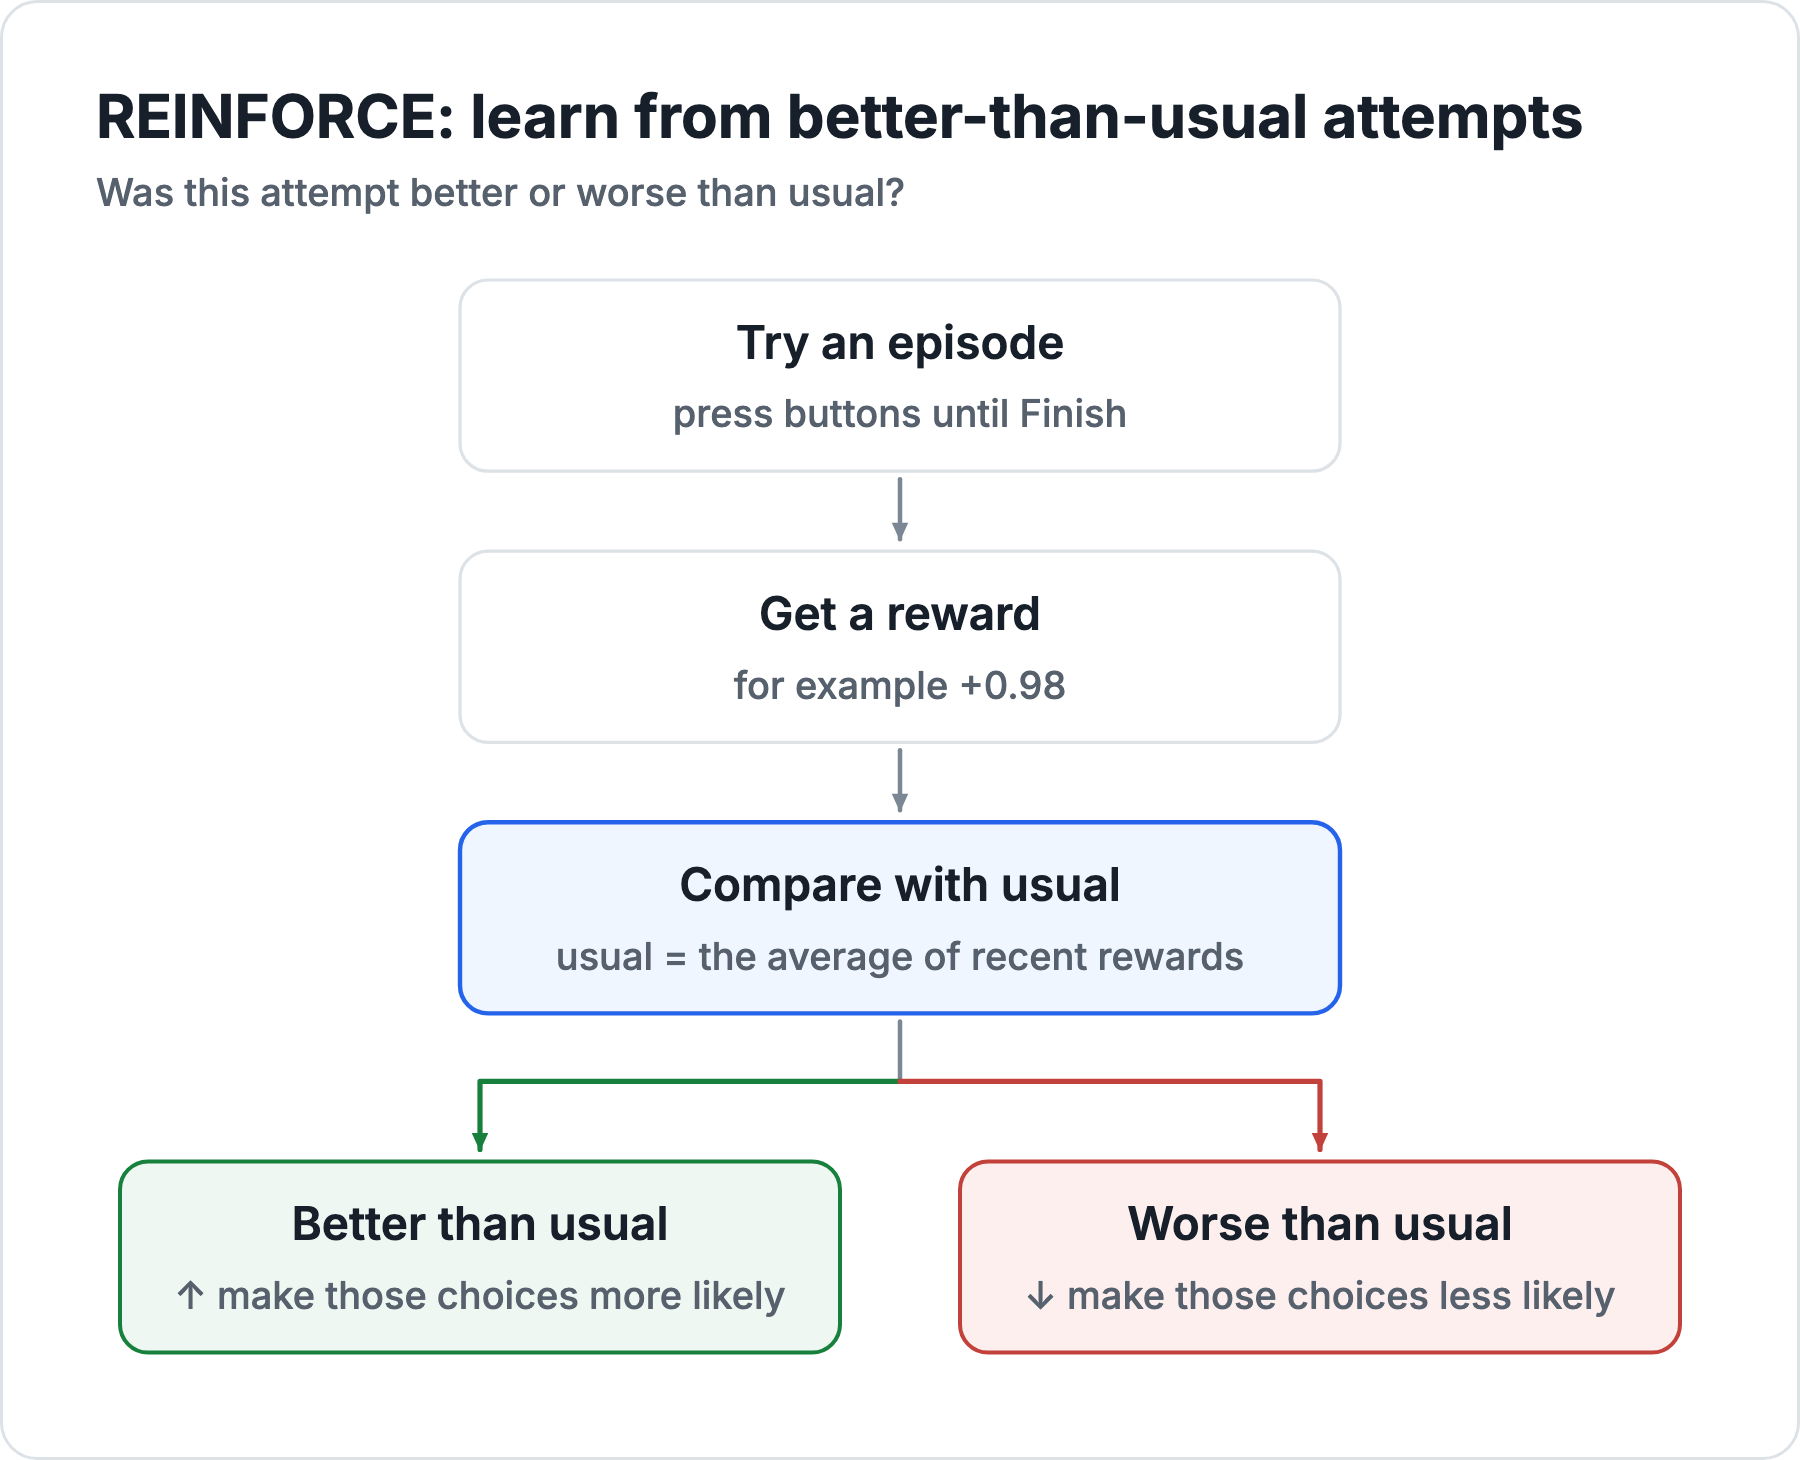

### A worked example

Say the agent's recent attempts scored about **+0.20** on average.

- It presses **Calculator → Finish** and scores **+0.98**. That's better than usual by 0.98 − 0.20 = **+0.78**, so both choices become **more likely**.
- Next time it presses **Finish** straight away and scores **−1.00**. That's worse than usual by −1.00 − 0.20 = **−1.20**, so that early Finish becomes **less likely**.

Two names for these ideas:

- The usual score is the **baseline**. We keep it as a running average of recent rewards.
- *Episode reward − baseline* is the **advantage**: positive means better than usual, negative means worse.

### The math (one line)

$$\text{loss} = -\,(R - b)\,\sum_{t} \log \pi(a_t \mid s_t)$$

| Symbol | In plain words |
|:--|:--|
| $R$ | the total reward of this episode |
| $b$ | the baseline: the usual reward |
| $R - b$ | the advantage: better (+) or worse (−) than usual |
| $\pi(a_t \mid s_t)$ | the probability the agent gave to the button it pressed at step $t$ |
| $\sum_t \log \pi(\cdot)$ | add up the log-probs of every choice in the episode |

PyTorch always *minimizes* a loss. Because of the minus sign, minimizing it **raises** the log-probs when the advantage is positive and **lowers** them when it is negative.

And here is the same line in code:

In [10]:
def reinforce_update(optimizer, log_probs, total_reward, baseline):
    advantage = total_reward - baseline
    loss = -(advantage * log_probs.sum())
    optimizer.zero_grad()
    loss.backward()     # work out how to nudge every preference
    optimizer.step()    # apply the nudge

💡 **Notice:** the whole episode gets **one** score, and every choice in it shares the credit. LLM agent training works the same way: a whole answer, maybe hundreds of tokens and several tool calls, gets one reward at the end.

## 6 · Before learning: how good is it? 📏

The same fair test as in Chapter 1: the three unseen questions, 100 tries each, with no learning.

In [11]:
def test_accuracy(policy, questions, repeats=100):
    with torch.no_grad():
        outcomes = [run_episode(policy, task)[2]
                    for task in questions for _ in range(repeats)]
    return sum(outcomes) / len(outcomes)

before = test_accuracy(policy, test_tasks)
print(f"Before training: {before:.0%} of tasks completed")

Before training: 19% of tasks completed


**What just happened?** With random buttons, the agent finishes correctly only about **1 time in 5**, by luck.

## 7 · Time to train! 🎯

Each round: pick a practice question → play an episode → apply the REINFORCE rule → update the baseline.

We also record the probability of the right first button for math (**Calculator**) and the right second button (**Finish**), so we can watch the brain change.

In [12]:
TRAIN_ROUNDS = 600   # 👈 try 100 or 1000
LEARNING_RATE = 0.1  # 👈 try 0.01 or 0.5

policy = new_policy()
optimizer = torch.optim.Adam([policy], lr=LEARNING_RATE)
baseline = 0.0
history, p_calculator, p_finish = [], [], []

for round_number in range(TRAIN_ROUNDS):
    task = random.choice(practice)
    total, log_probs, success, _ = run_episode(policy, task)
    reinforce_update(optimizer, log_probs, total, baseline)
    baseline = 0.9 * baseline + 0.1 * total  # running average of recent rewards

    history.append(int(success))
    with torch.no_grad():
        p_calculator.append(probabilities(policy, ("math", "needs_tool"))[0].item())
        p_finish.append(probabilities(policy, ("math", "has_answer"))[3].item())
print("Practice complete! 🎉")

Practice complete! 🎉


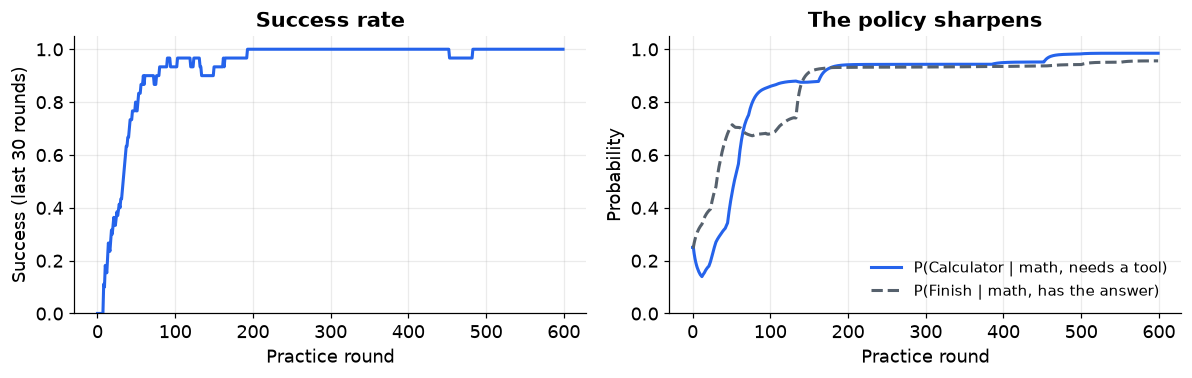

In [13]:
recent = [sum(history[max(0, i-29):i+1]) / min(30, i+1) for i in range(len(history))]
fig, (left, right) = plt.subplots(1, 2, figsize=(11, 3.6))
left.plot(recent, color=ACCENT, linewidth=2)
left.set(ylim=(0, 1.05), xlabel="Practice round", ylabel="Success (last 30 rounds)", title="Success rate")
right.plot(p_calculator, color=ACCENT, linewidth=2, label="P(Calculator | math, needs a tool)")
right.plot(p_finish, color="#56616D", linewidth=2, linestyle="--", label="P(Finish | math, has the answer)")
right.set(ylim=(0, 1.05), xlabel="Practice round", ylabel="Probability", title="The policy sharpens")
right.legend(loc="lower right", fontsize=10, frameon=False)
for ax in (left, right):
    ax.grid(alpha=0.25)
plt.tight_layout()
plt.show()

**What just happened?** Both probabilities start at 25% (a blind guess) and climb toward 100% as better-than-usual episodes get reinforced. The success rate rises with them.

## 8 · Peek inside the brain 🔎

Each row is a situation and each column is a button. Darker means more likely.

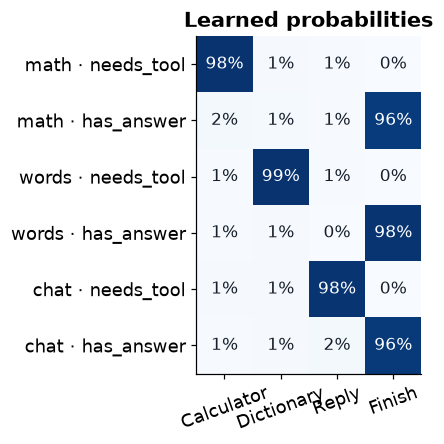

In [14]:
with torch.no_grad():
    table = torch.softmax(policy, dim=1).numpy()
fig, ax = plt.subplots(figsize=(7.5, 4.2))
ax.imshow(table, cmap="Blues", vmin=0, vmax=1)
ax.set_xticks(range(len(buttons)), buttons, rotation=20)
ax.set_yticks(range(len(states)), [f"{t} · {s}" for t, s in states])
for i in range(len(states)):
    for j in range(len(buttons)):
        ax.text(j, i, f"{table[i, j]:.0%}", ha="center", va="center",
                color="white" if table[i, j] > 0.6 else "#17202A", fontsize=11)
ax.set_title("Learned probabilities")
plt.tight_layout()
plt.show()

**What just happened?** The agent learned the same two-step plan as in Chapter 1, **right tool → Finish**, but now as probabilities instead of scores.

## 9 · The big reveal: before vs. after 🏆

Before: 19% completed
After:  99% completed


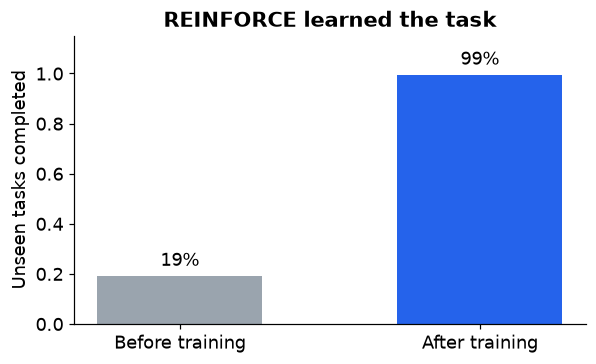

In [15]:
after = test_accuracy(policy, test_tasks)
print(f"Before: {before:.0%} completed")
print(f"After:  {after:.0%} completed")

plt.figure(figsize=(6, 3.4))
bars = plt.bar(["Before training", "After training"], [before, after], color=[GREY, ACCENT], width=0.55)
plt.bar_label(bars, labels=[f"{before:.0%}", f"{after:.0%}"], padding=4, fontsize=12)
plt.ylim(0, 1.15)
plt.ylabel("Unseen tasks completed")
plt.title("REINFORCE learned the task")
plt.show()

**What just happened?** On questions it never practiced on, the agent went from luck to nearly always right, using nothing but rewards.

## 10 · Why subtract a baseline? An experiment 🧪

Imagine a very generous teacher who gives **+3 bonus points to every attempt**, even terrible ones.

- **Without a baseline**, every attempt now looks "good", so the agent reinforces its mistakes too. It can still tell good from bad, but only faintly.
- **With a baseline**, the bonus quickly becomes part of "usual", so only better-than-usual attempts get reinforced.

We train 8 fresh agents for each setting and average their learning curves. This takes about 20 seconds.

In [16]:
def train_agent(rounds=300, bonus=0.0, use_baseline=True, seed=0):
    random.seed(seed)
    torch.manual_seed(seed)
    policy = new_policy()
    optimizer = torch.optim.Adam([policy], lr=0.1)
    baseline, wins = 0.0, []
    for _ in range(rounds):
        total, log_probs, success, _ = run_episode(policy, random.choice(practice))
        total += bonus
        reinforce_update(optimizer, log_probs, total, baseline if use_baseline else 0.0)
        baseline = 0.9 * baseline + 0.1 * total
        wins.append(success)
    return policy, wins

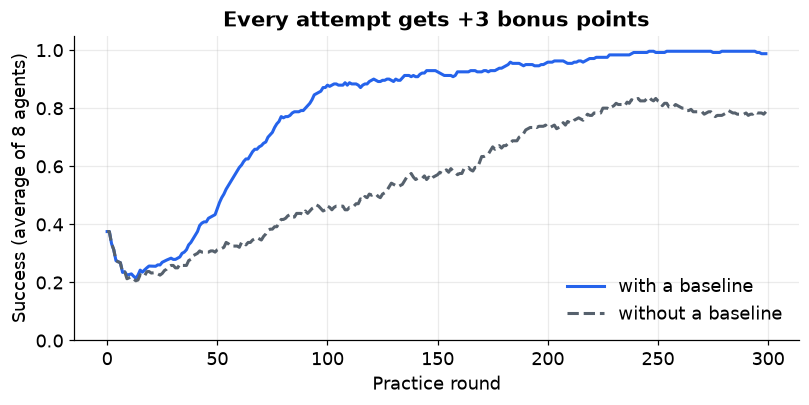

In [17]:
def smooth(wins, window=30):
    return [sum(wins[max(0, i-window+1):i+1]) / min(window, i+1) for i in range(len(wins))]

plt.figure(figsize=(8.5, 3.6))
for use_baseline, color, style in [(True, ACCENT, "-"), (False, "#56616D", "--")]:
    curves = [smooth(train_agent(bonus=3.0, use_baseline=use_baseline, seed=s)[1]) for s in range(8)]
    mean_curve = [sum(c[i] for c in curves) / len(curves) for i in range(len(curves[0]))]
    label = "with a baseline" if use_baseline else "without a baseline"
    plt.plot(mean_curve, color=color, linestyle=style, linewidth=2, label=label)
plt.ylim(0, 1.05)
plt.xlabel("Practice round")
plt.ylabel("Success (average of 8 agents)")
plt.title("Every attempt gets +3 bonus points")
plt.legend(frameon=False)
plt.grid(alpha=0.25)
plt.show()

**What just happened?** The solid line (with a baseline) climbs to nearly 100%. The dashed line (without one) crawls up much more slowly.

**Takeaway:** a baseline doesn't change *what* is good. It makes the signal **clearer**. In the next chapter, GRPO uses an even smarter baseline: it lets the agent try **the same question several times** and compares the attempts with each other.

## 11 · Your turn: small experiments 🧪

1. **Learning rate:** change `LEARNING_RATE = 0.1` to `0.01`. How many rounds does it need now? What about `0.5`?
2. **Change a reward and see what happens:** in `step`, change the penalty for finishing without an answer from `-1` to `0`. Does the agent still learn to use a tool first?
3. **Mean teacher:** in the experiment, change `bonus=3.0` to `bonus=-3.0`. Does the baseline still help?

After changing an earlier cell, use **Runtime → Restart and run all** for a clean experiment.

## 12 · How this connects to LLMs 🚀

| In this notebook | In LLM agentic RL (Chapter 4) |
|:--|:--|
| Choose one of 4 buttons | Choose one of ~150,000 tokens |
| Softmax over 4 preferences | Softmax over the model's output |
| One episode = a few button presses | One episode = a whole answer with tool calls |
| One reward for the episode | One reward for the whole answer |
| `loss = -(advantage * log_probs.sum())` | **The same line**, summed over the answer's tokens |

Everything else in LLM training is about making this line **stable and efficient**, and that's exactly what GRPO adds in Chapter 3.

## 🎓 Congratulations: you trained a policy-gradient agent!

- ✅ **Policies:** an agent can learn *probabilities* instead of scores.
- ✅ **Softmax and log-probs:** how preferences become probabilities, and how we measure "how likely was that?"
- ✅ **REINFORCE:** better-than-usual attempts become more likely, worse ones less likely.
- ✅ **Baselines:** comparing against "usual" makes learning faster and steadier.

**One-sentence takeaway:** *Policy gradients nudge the probability of each choice up or down depending on whether the attempt beat expectations.*

### ➡️ Next: [Ch 3 · GRPO](https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/03_grpo_from_scratch.ipynb)

<a href="https://colab.research.google.com/github/HamedKhosravi99/Train-Your-RL-Agent/blob/main/notebooks/03_grpo_from_scratch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

⭐ Found this useful? [Star Train Your RL Agent on GitHub](https://github.com/HamedKhosravi99/Train-Your-RL-Agent) so other beginners can find it.